# Phase 5: Forecasting Models with Time-Based Validation

**Project:** FMCG Global Demand Planning Capstone
**Input:** `data/fmcg_features.parquet` (or `.csv`) from Phase 4
**Output:** model comparison table, the best model, test-set predictions

## Goal
Train **Random Forest**, **LightGBM** and **XGBoost** to forecast daily `units_sold` per store-SKU, and show whether they beat the best naive baseline from Phase 4 (`roll_mean_30`, WAPE about 0.316 on the test set).

## Plan
1. **Expanding-window cross-validation** (inside 2021-2022) to compare the three model families fairly.
2. **Tuning** LightGBM and XGBoost on the validation period (Jan-Jun 2023) with **early stopping**.
3. **Final test** (Jul-Dec 2023): refit on train + validation, predict the test period **once**, and compare with the baseline.
4. **Diagnostics:** where does the best model do well or badly (ABC class, category, promo, weekday, month, stock-out days)?
5. **Save** the best model for Phase 6 (SHAP explainability).

## Rules that protect the results
- **Never shuffle time series.** Every split trains on the past and predicts the future.
- **The test set is used once**, at the end. All choices (model, settings) are made on earlier data.
- Metrics are **WAPE** (total absolute error / total actual units, lower is better), **MAE**, **RMSE** and **Bias** (are we over- or under-forecasting in total?).

## 1. Setup

In [1]:
# Run once. If everything is already installed this just reports "Requirement already satisfied".
%pip install lightgbm xgboost scikit-learn pyarrow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (10, 4)

os.makedirs("../models", exist_ok=True)
os.makedirs("../reports", exist_ok=True)
SEED = 42

## 2. Load the Phase 4 feature table
We add one extra column, `so_today` (was there a stock-out **today**), but **only for evaluation**. It is never given to a model as a feature, because it is only known after the day ends. It lets us check how the models do on days with and without stock-outs.

In [3]:
try:
    feats = pd.read_parquet("../data/fmcg_features.parquet")
except Exception:
    feats = pd.read_csv("../data/fmcg_features.csv", parse_dates=["date"])

target = "units_sold"
id_cols = ["series_id", "date"]
feature_cols = [c for c in feats.columns if c not in id_cols + [target]]
print("Rows:", f"{len(feats):,}", "| Features:", len(feature_cols))

# Evaluation-only information (NOT used as model input).
flag = pd.read_csv("../data/fmcg_clean.csv",
                   usecols=["store_id", "sku_id", "date", "category", "stock_out_flag"],
                   parse_dates=["date"])
flag["series_id"] = flag["store_id"] + "_" + flag["sku_id"]
cat_names = dict(enumerate(sorted(flag["category"].unique())))   # matches Phase 4 label encoding

feats = feats.merge(
    flag[["series_id", "date", "stock_out_flag"]].rename(columns={"stock_out_flag": "so_today"}),
    on=["series_id", "date"], how="left")
print("Rows with missing stock-out flag:", feats["so_today"].isna().sum())

Rows: 1,069,850 | Features: 31
Rows with missing stock-out flag: 0


## 3. Metrics and the three splits
**WAPE** = sum of absolute errors / sum of actual units. 0.30 means the forecast errors add up to 30% of total demand. **Bias** = (total forecast - total actual) / total actual; positive means over-forecasting, which ties up inventory, negative means under-forecasting, which risks stock-outs. Predictions are clipped at 0 because units cannot be negative.

In [4]:
def metrics(y, p):
    y = np.asarray(y, dtype=float)
    p = np.clip(np.asarray(p, dtype=float), 0, None)
    return {"WAPE": np.abs(y - p).sum() / y.sum(),
            "MAE": np.abs(y - p).mean(),
            "RMSE": np.sqrt(((y - p) ** 2).mean()),
            "Bias_%": (p.sum() - y.sum()) / y.sum() * 100}

train = feats[feats["date"] <= "2022-12-31"]
valid = feats[(feats["date"] >= "2023-01-01") & (feats["date"] <= "2023-06-30")]
test  = feats[feats["date"] >= "2023-07-01"]

for name, part in [("train", train), ("validation", valid), ("test", test)]:
    print(f"{name:11s} {part['date'].min().date()} to {part['date'].max().date()}  rows: {len(part):,}")

print("\nBaseline roll_mean_30 (from Phase 4):")
print("  validation:", {k: round(v, 3) for k, v in metrics(valid[target], valid["roll_mean_30"]).items()})
print("  test:      ", {k: round(v, 3) for k, v in metrics(test[target], test["roll_mean_30"]).items()})

train       2021-01-31 to 2022-12-31  rows: 703,390
validation  2023-01-01 to 2023-06-30  rows: 181,724
test        2023-07-01 to 2023-12-31  rows: 184,736

Baseline roll_mean_30 (from Phase 4):
  validation: {'WAPE': np.float64(0.313), 'MAE': np.float64(18.107), 'RMSE': np.float64(28.318), 'Bias_%': np.float64(-0.016)}
  test:       {'WAPE': np.float64(0.316), 'MAE': np.float64(19.12), 'RMSE': np.float64(30.224), 'Bias_%': np.float64(-0.066)}


## 4. Model definitions
Three tree-based model families. All of them learn rules such as "if the 30-day average is high and a promotion is on, expect more units".
- **Random Forest:** many independent decision trees averaged together. Robust but slower on large data, so we train it on a random sample of the training rows (every sampled row is still from the training period, so there is no leakage).
- **LightGBM** and **XGBoost:** *gradient boosting*. Trees are built one after another, each correcting the errors of the previous ones. Usually the most accurate on tabular data like this.

The settings below are sensible defaults; Section 6 tunes the boosting models on the validation period.

In [5]:
def make_rf():
    return RandomForestRegressor(n_estimators=100, max_depth=14, min_samples_leaf=50,
                                 max_features=0.5, n_jobs=-1, random_state=SEED)

def make_lgbm(**kw):
    params = dict(n_estimators=400, learning_rate=0.05, num_leaves=63, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, min_child_samples=50,
                  importance_type="gain", random_state=SEED, n_jobs=-1, verbose=-1)
    params.update(kw)
    return lgb.LGBMRegressor(**params)

def make_xgb(**kw):
    params = dict(n_estimators=400, learning_rate=0.05, max_depth=8, subsample=0.8,
                  colsample_bytree=0.8, min_child_weight=50, tree_method="hist",
                  random_state=SEED, n_jobs=-1)
    params.update(kw)
    return xgb.XGBRegressor(**params)

RF_SAMPLE = 250_000   # rows used to train the Random Forest (speed)

def fit_predict(name, train_df, pred_df):
    """Fit a model on train_df and predict pred_df. Returns (model, predictions)."""
    if name == "RandomForest":
        tr = train_df.sample(min(RF_SAMPLE, len(train_df)), random_state=SEED)
        model = make_rf()
    else:
        tr = train_df
        model = make_lgbm() if name == "LightGBM" else make_xgb()
    model.fit(tr[feature_cols], tr[target])
    return model, model.predict(pred_df[feature_cols])

## 5. Expanding-window cross-validation (model families, default settings)
One validation period can be lucky or unlucky, so we test on **four consecutive quarters of 2022**. Each fold trains on *everything before* its validation quarter, so the training window grows and the validation always lies in the future:

| Fold | Train up to | Validate on |
|---|---|---|
| 1 | 2021-12-31 | 2022 Q1 |
| 2 | 2022-03-31 | 2022 Q2 |
| 3 | 2022-06-30 | 2022 Q3 |
| 4 | 2022-09-30 | 2022 Q4 |

Folds 3 and 4 include the Beverages summer peak and the Snacks year-end peak, the hardest periods. This step can take 10-20 minutes in total; set `RUN_CV = False` to skip it.

In [6]:
RUN_CV = True

folds = [("2021-12-31", "2022-01-01", "2022-03-31"),
         ("2022-03-31", "2022-04-01", "2022-06-30"),
         ("2022-06-30", "2022-07-01", "2022-09-30"),
         ("2022-09-30", "2022-10-01", "2022-12-31")]

cv_rows = []
if RUN_CV:
    for i, (tr_end, va_start, va_end) in enumerate(folds, 1):
        tr = feats[feats["date"] <= tr_end]
        va = feats[(feats["date"] >= va_start) & (feats["date"] <= va_end)]
        base = metrics(va[target], va["roll_mean_30"])["WAPE"]
        cv_rows.append({"fold": i, "model": "Baseline roll_mean_30", "WAPE": base})
        for name in ["RandomForest", "LightGBM", "XGBoost"]:
            t0 = time.time()
            _, pred = fit_predict(name, tr, va)
            m = metrics(va[target], pred)
            cv_rows.append({"fold": i, "model": name, "WAPE": m["WAPE"]})
            print(f"fold {i} {name:12s} WAPE {m['WAPE']:.3f}  ({time.time()-t0:.0f}s)")

if cv_rows:
    cv = pd.DataFrame(cv_rows)
    cv_table = cv.pivot(index="model", columns="fold", values="WAPE")
    cv_table["mean"] = cv_table.mean(axis=1)
    cv_table["std"] = cv_table[[1, 2, 3, 4]].std(axis=1)
    print("\nWAPE by fold (lower is better):")
    print(cv_table.sort_values("mean").round(3))

fold 1 RandomForest WAPE 0.271  (94s)
fold 1 LightGBM     WAPE 0.269  (22s)
fold 1 XGBoost      WAPE 0.269  (84s)
fold 2 RandomForest WAPE 0.272  (88s)
fold 2 LightGBM     WAPE 0.268  (54s)
fold 2 XGBoost      WAPE 0.268  (28s)
fold 3 RandomForest WAPE 0.274  (85s)
fold 3 LightGBM     WAPE 0.268  (23s)
fold 3 XGBoost      WAPE 0.268  (74s)
fold 4 RandomForest WAPE 0.272  (66s)
fold 4 LightGBM     WAPE 0.268  (62s)
fold 4 XGBoost      WAPE 0.268  (23s)

WAPE by fold (lower is better):
fold                      1     2     3     4  mean   std
model                                                    
XGBoost               0.269 0.268 0.268 0.268 0.268 0.000
LightGBM              0.269 0.268 0.268 0.268 0.268 0.001
RandomForest          0.271 0.272 0.274 0.272 0.272 0.001
Baseline roll_mean_30 0.313 0.313 0.317 0.310 0.313 0.003


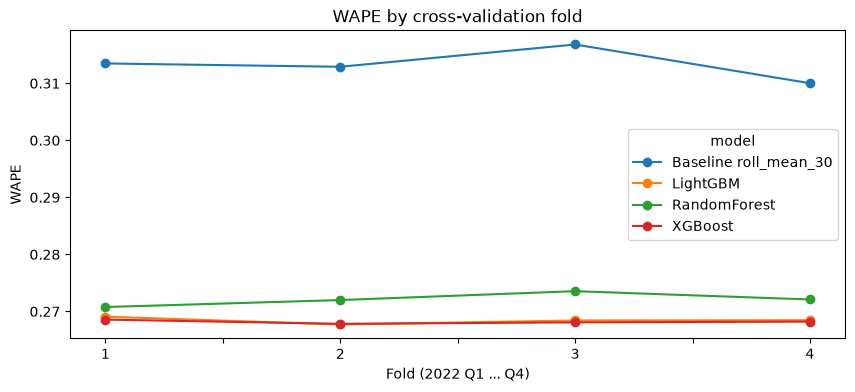

In [7]:
if cv_rows:
    cv_table.drop(columns=["mean", "std"]).T.plot(marker="o", title="WAPE by cross-validation fold")
    plt.xlabel("Fold (2022 Q1 ... Q4)")
    plt.ylabel("WAPE")
    plt.show()

## 6. Tuning on the validation period (Jan-Jun 2023)
We try a small grid for LightGBM and XGBoost: tree size and the loss function.
- **Squared error** (default) penalises big misses heavily.
- **Poisson** loss is designed for counts such as units sold and often suits demand data.

**Early stopping:** we allow up to 1,000 trees but stop when the validation error has not improved for 50 rounds. This picks the number of trees automatically and prevents overfitting (memorising the training data).

In [8]:
tune_rows = []
best_iters = {}

lgb_grid = [dict(num_leaves=nl, objective=obj)
            for obj in ["regression", "poisson"] for nl in [31, 63, 127]]
for cfg in lgb_grid:
    t0 = time.time()
    m = make_lgbm(n_estimators=1000, **cfg)
    m.fit(train[feature_cols], train[target],
          eval_set=[(valid[feature_cols], valid[target])], eval_metric="l1",
          callbacks=[lgb.early_stopping(50, verbose=False)])
    pred = m.predict(valid[feature_cols])
    key = f"LightGBM {cfg['objective']} leaves={cfg['num_leaves']}"
    best_iters[key] = m.best_iteration_
    tune_rows.append({"config": key, "family": "LightGBM", **cfg, "trees": m.best_iteration_,
                      "valid_WAPE": metrics(valid[target], pred)["WAPE"]})
    print(f"{key:40s} trees {m.best_iteration_:4d}  WAPE {tune_rows[-1]['valid_WAPE']:.3f}  ({time.time()-t0:.0f}s)")

xgb_grid = [dict(max_depth=d, objective=obj)
            for obj in ["reg:squarederror", "count:poisson"] for d in [6, 8, 10]]
for cfg in xgb_grid:
    t0 = time.time()
    m = make_xgb(n_estimators=1000, early_stopping_rounds=50, eval_metric="mae", **cfg)
    m.fit(train[feature_cols], train[target],
          eval_set=[(valid[feature_cols], valid[target])], verbose=False)
    pred = m.predict(valid[feature_cols])
    key = f"XGBoost {cfg['objective']} depth={cfg['max_depth']}"
    best_iters[key] = m.best_iteration + 1
    tune_rows.append({"config": key, "family": "XGBoost", **cfg, "trees": m.best_iteration + 1,
                      "valid_WAPE": metrics(valid[target], pred)["WAPE"]})
    print(f"{key:40s} trees {m.best_iteration+1:4d}  WAPE {tune_rows[-1]['valid_WAPE']:.3f}  ({time.time()-t0:.0f}s)")

tune = pd.DataFrame(tune_rows).sort_values("valid_WAPE")
print("\nTuning results (lower WAPE is better):")
print(tune[["config", "trees", "valid_WAPE"]].round(3).to_string(index=False))

LightGBM regression leaves=31            trees  971  WAPE 0.267  (109s)
LightGBM regression leaves=63            trees  475  WAPE 0.267  (76s)
LightGBM regression leaves=127           trees  348  WAPE 0.267  (42s)
LightGBM poisson leaves=31               trees  998  WAPE 0.267  (131s)
LightGBM poisson leaves=63               trees  997  WAPE 0.266  (130s)
LightGBM poisson leaves=127              trees  699  WAPE 0.266  (204s)
XGBoost reg:squarederror depth=6         trees  727  WAPE 0.267  (64s)
XGBoost reg:squarederror depth=8         trees  512  WAPE 0.267  (75s)
XGBoost reg:squarederror depth=10        trees  273  WAPE 0.267  (52s)
XGBoost count:poisson depth=6            trees  999  WAPE 0.267  (122s)
XGBoost count:poisson depth=8            trees  830  WAPE 0.266  (131s)
XGBoost count:poisson depth=10           trees  526  WAPE 0.267  (101s)

Tuning results (lower WAPE is better):
                           config  trees  valid_WAPE
      LightGBM poisson leaves=127    699       0

### 6.1 Random Forest on the validation period
Random Forest has no early stopping, so we run it once with its default settings for a fair validation score. Then we pick the best configuration of each family.

In [9]:
t0 = time.time()
rf_val_model, rf_val_pred = fit_predict("RandomForest", train, valid)
rf_val = metrics(valid[target], rf_val_pred)
print(f"RandomForest validation WAPE {rf_val['WAPE']:.3f}  ({time.time()-t0:.0f}s)")

best_lgb = tune[tune["family"] == "LightGBM"].iloc[0]
best_xgb = tune[tune["family"] == "XGBoost"].iloc[0]

validation_scores = {
    "RandomForest": rf_val["WAPE"],
    "LightGBM": best_lgb["valid_WAPE"],
    "XGBoost": best_xgb["valid_WAPE"],
}
best_name = min(validation_scores, key=validation_scores.get)
print("\nValidation WAPE by family:", {k: round(v, 3) for k, v in validation_scores.items()})
print("Best family on validation:", best_name)

RandomForest validation WAPE 0.272  (71s)

Validation WAPE by family: {'RandomForest': np.float64(0.272), 'LightGBM': np.float64(0.266), 'XGBoost': np.float64(0.266)}
Best family on validation: LightGBM


## 7. Final test (Jul-Dec 2023), used once
Now each model is **refit on train + validation** (all data before July 2023, so it has seen the most recent months) with the settings chosen above, then predicts the test period. Boosting models use the number of trees found by early stopping.

The model choice was made on validation data only; the test numbers are an honest estimate of future performance.

In [10]:
train_valid = pd.concat([train, valid])
final_models, test_preds = {}, {}

# LightGBM with the best validation settings
cfg = {"num_leaves": int(best_lgb["num_leaves"]), "objective": best_lgb["objective"]}
m = make_lgbm(n_estimators=int(best_lgb["trees"]), **cfg)
m.fit(train_valid[feature_cols], train_valid[target])
final_models["LightGBM"], test_preds["LightGBM"] = m, m.predict(test[feature_cols])

# XGBoost with the best validation settings
cfg = {"max_depth": int(best_xgb["max_depth"]), "objective": best_xgb["objective"]}
m = make_xgb(n_estimators=int(best_xgb["trees"]), **cfg)
m.fit(train_valid[feature_cols], train_valid[target])
final_models["XGBoost"], test_preds["XGBoost"] = m, m.predict(test[feature_cols])

# Random Forest
final_models["RandomForest"], test_preds["RandomForest"] = fit_predict("RandomForest", train_valid, test)

rows = [{"model": "Baseline roll_mean_30", **metrics(test[target], test["roll_mean_30"])}]
for name, pred in test_preds.items():
    rows.append({"model": name, **metrics(test[target], pred)})
results = pd.DataFrame(rows).set_index("model")
results["improvement_vs_baseline_%"] = (1 - results["WAPE"] / results.loc["Baseline roll_mean_30", "WAPE"]) * 100

print("TEST SET (Jul-Dec 2023):")
print(results.round(3))
results.to_csv("../reports/model_comparison_test.csv")

/home/brian/miniconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/brian/miniconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/brian/miniconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/brian/miniconda3/lib/python3.14/site-packages/sklearn/utils/paralle

TEST SET (Jul-Dec 2023):
                       WAPE    MAE   RMSE  Bias_%  improvement_vs_baseline_%
model                                                                       
Baseline roll_mean_30 0.316 19.120 30.224  -0.066                      0.000
LightGBM              0.267 16.151 24.667   0.009                     15.527
XGBoost               0.267 16.162 24.706  -0.071                     15.468
RandomForest          0.273 16.552 25.380   0.240                     13.429


In [17]:
# Fair comparison on normal days only (stock-out days distort sales, not demand).
mask = (test["so_today"] == 0).values
rows = [{"model": "Baseline roll_mean_30",
         **metrics(test[target].values[mask], test["roll_mean_30"].values[mask])}]
for name, pred in test_preds.items():
    rows.append({"model": name, **metrics(test[target].values[mask], pred[mask])})
normal = pd.DataFrame(rows).set_index("model")
print("Test set, non-stock-out days only:")
print(normal.round(3))

Test set, non-stock-out days only:
                       WAPE    MAE   RMSE  Bias_%
model                                            
Baseline roll_mean_30 0.293 18.207 28.954  -2.483
LightGBM              0.244 15.144 22.815  -2.412
XGBoost               0.244 15.157 22.867  -2.491
RandomForest          0.251 15.554 23.618  -2.185


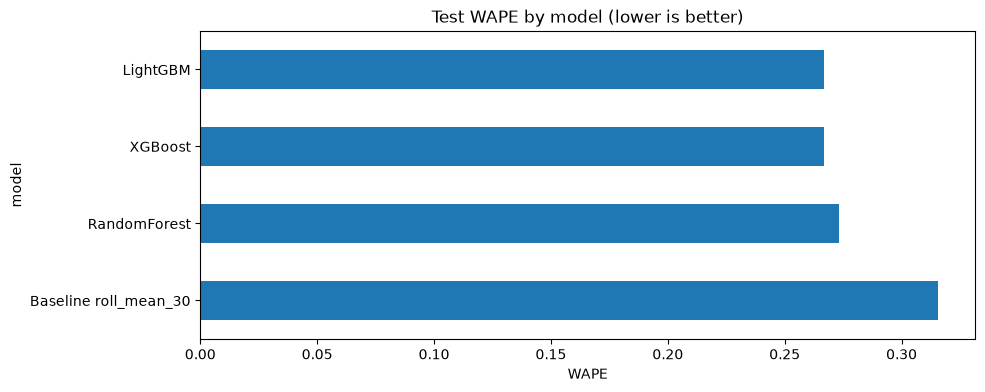

In [11]:
results["WAPE"].sort_values(ascending=False).plot(kind="barh", title="Test WAPE by model (lower is better)")
plt.xlabel("WAPE")
plt.show()

## 8. Diagnostics: where does the best model work and where does it struggle?
We take the model that was best on **validation** and break its test errors down by segment. A planner needs to know not just the average accuracy but also where the forecast is unreliable.

In [12]:
best_pred = np.clip(test_preds[best_name], 0, None)
te = test[["series_id", "date", target, "abc_code", "category_code", "promo_flag",
           "discount_pct", "weekday", "month", "so_today"]].copy()
te["y"] = te[target]
te["pred"] = best_pred
te["abs_err"] = (te["y"] - te["pred"]).abs()
te["err"] = te["pred"] - te["y"]
te["abc"] = te["abc_code"].map({0: "A", 1: "B", 2: "C"})
te["category"] = te["category_code"].map(cat_names)

def seg_table(by):
    t = te.groupby(by).agg(rows=("y", "size"), actual=("y", "sum"),
                           abs_err=("abs_err", "sum"), err=("err", "sum"))
    t["WAPE"] = t["abs_err"] / t["actual"]
    t["Bias_%"] = t["err"] / t["actual"] * 100
    return t[["rows", "WAPE", "Bias_%"]]

print(f"Best model on validation: {best_name}\n")
for by in ["abc", "category", "promo_flag", "so_today", "weekday"]:
    print(f"--- by {by} ---")
    print(seg_table(by).round(3).to_string())
    print()

Best model on validation: LightGBM

--- by abc ---
      rows  WAPE  Bias_%
abc                     
A    88320 0.266   0.055
B    52440 0.270  -0.027
C    43976 0.264  -0.119

--- by category ---
                rows  WAPE  Bias_%
category                          
Beverages      44712 0.268   0.329
Dairy          32936 0.263  -0.069
Home Care      29624 0.265   0.023
Personal Care  33488 0.265   0.101
Snacks         43976 0.270  -0.355

--- by promo_flag ---
              rows  WAPE  Bias_%
promo_flag                      
0           169948 0.267   0.115
1            14788 0.267  -0.624

--- by so_today ---
            rows  WAPE  Bias_%
so_today                      
0         179239 0.244  -2.412
1           5497 4.036 403.566

--- by weekday ---
          rows  WAPE  Bias_%
weekday                     
0        26104 0.266   0.017
1        26104 0.269  -0.096
2        26104 0.264  -0.157
3        26104 0.265  -0.125
4        26104 0.265   0.187
5        27108 0.269  -0.060
6     

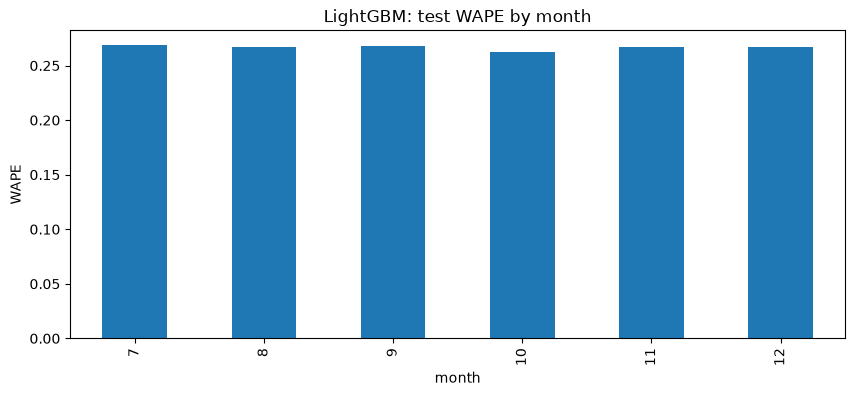

Discount depth (promo rows only):
              rows  WAPE  Bias_%
discount_pct                    
0.100         3547 0.269   0.360
0.150         4023 0.266  -1.337
0.200         3558 0.272   0.637
0.300         3660 0.264  -1.773


In [13]:
seg_table("month")["WAPE"].plot(kind="bar", title=f"{best_name}: test WAPE by month")
plt.ylabel("WAPE")
plt.show()

print("Discount depth (promo rows only):")
print(seg_table(te["discount_pct"].where(te["promo_flag"] == 1)).round(3).to_string())

### 8.1 Actual vs predicted, and feature importance
A good forecast lies close to the diagonal line. The importance chart shows which inputs the model relied on most (total improvement each feature gave to the model). SHAP in Phase 6 gives a more rigorous explanation.

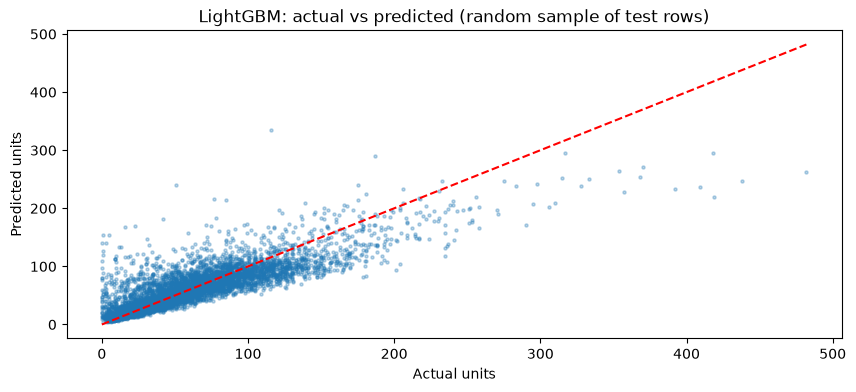

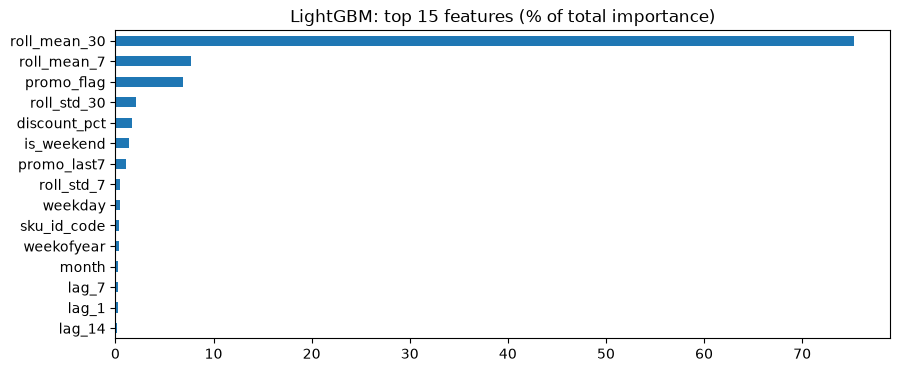

In [14]:
samp = te.sample(6000, random_state=SEED)
plt.scatter(samp["y"], samp["pred"], s=5, alpha=0.3)
lim = max(samp["y"].max(), samp["pred"].max())
plt.plot([0, lim], [0, lim], color="red", linestyle="--")
plt.xlabel("Actual units")
plt.ylabel("Predicted units")
plt.title(f"{best_name}: actual vs predicted (random sample of test rows)")
plt.show()

imp = pd.Series(final_models[best_name].feature_importances_, index=feature_cols)
(imp / imp.sum() * 100).sort_values().tail(15).plot(kind="barh", title=f"{best_name}: top 15 features (% of total importance)")
plt.show()

## 9. Save the best model and outputs for Phase 6

In [15]:
import joblib

model = final_models[best_name]
if best_name == "LightGBM":
    model.booster_.save_model("../models/best_model.txt")
    saved = "models/best_model.txt"
elif best_name == "XGBoost":
    model.save_model("../models/best_model.json")
    saved = "models/best_model.json"
else:
    joblib.dump(model, "../models/best_model.joblib", compress=3)
    saved = "models/best_model.joblib"

with open("../models/feature_cols.json", "w") as f:
    json.dump({"best_model": best_name, "features": feature_cols, "target": target}, f, indent=2)

te[["series_id", "date", "y", "pred"]].to_csv("../data/test_predictions.csv", index=False)
tune.to_csv("../reports/tuning_results.csv", index=False)

print("Saved:", saved, "| models/feature_cols.json | data/test_predictions.csv | reports/*.csv")

Saved: models/best_model.txt | models/feature_cols.json | data/test_predictions.csv | reports/*.csv


## 10. Summary of findings

**Cross-validation (expanding windows over 2022 Q1-Q4)**
- Mean WAPE: XGBoost 0.268, LightGBM 0.268, Random Forest 0.272, baseline roll_mean_30 0.313. The ranking was identical in all four folds (std 0.000-0.003), including the summer and year-end quarters, so the result is stable.

**Tuning (validation Jan-Jun 2023)**
- All 12 LightGBM and XGBoost configurations scored 0.266-0.267 WAPE. Poisson loss was marginally better (0.266) than squared error (0.267), but the difference is within noise. Tree size and loss function barely mattered, which suggests the models are close to the noise floor of daily data. Several runs reached the 1,000-tree limit, so extra trees would add little.

**Final test (Jul-Dec 2023, used once, models refit on train + validation)**
- LightGBM WAPE 0.267 (MAE 16.2, bias +0.01%); XGBoost 0.267 (MAE 16.2, bias -0.07%); Random Forest 0.273 (MAE 16.6, bias +0.24%); baseline roll_mean_30 0.316 (MAE 19.1).
- The boosting models improve on the baseline by about 15.5% (13.4% for Random Forest). Test WAPE (0.267) matches validation (0.266), so there is no sign of overfitting. LightGBM was selected on validation; XGBoost ties it to three decimals.

**Diagnostics**
- Errors are uniform: WAPE is 0.26-0.27 for every ABC class, category, weekday and for promo vs non-promo days; biases are all under 0.7% in absolute value. Across discount depths WAPE is 0.264-0.272 with bias between -1.8% and +0.6%.
- **Stock-out days are the exception.** On the 5,497 stock-out rows (3.0% of the test set) the model predicts about 5 times the recorded sales (WAPE 4.04, bias +404%): it forecasts demand while recorded sales are capped by missing stock. On the 179,239 normal days WAPE is 0.244. The near-zero overall bias therefore combines a -2.4% bias on normal days with a large over-prediction on stock-out days.
- Actual-vs-predicted shows under-prediction of the highest-volume days (actual above about 200 units): predictions flatten around 250 even when actuals reach 400-500.

**Feature importance (LightGBM, gain)**
- roll_mean_30 about 75%, roll_mean_7 about 7.5%, promo_flag about 7%, then roll_std_30, discount_pct, is_weekend and promo_last7 at 1-2% each. Raw lags, weather, channel and country contribute almost nothing. The model mainly uses the series' recent level, adjusted for promotion and weekend, consistent with Phases 2-3.

**Implications and limitations**
- A forecast of demand is not a forecast of sales: planners should compare forecast demand with available supply, because stock-outs suppress recorded sales. Training only on non-stock-out days is a possible improvement.
- Peak-day demand is under-forecast; safety stock for high-volume series should account for this.
- Limitations: weather treated as known in advance; promotions and prices assumed planned ahead; one test period; the dataset appears very uniform (likely simulated), so gaps between segments may be smaller than in real data.